# 03_VisitSummary: do the bad visits stand out in `preliminary_visit_summary`?

Notebook 02 found visits where `single_visit_star` photometry disagrees strongly with the Monster (median offset 2-15 %, sigma_MAD 5-20 %), for example 2025051900119 (y), 2025052000091 (g) and 2025052900063 (z), next to clean visits of the same bands.

Here we read `preliminary_visit_summary` (stage 1, one row per detector) for the visits processed in notebook 02 and compare the quantities it holds (zero point, PSF size, sky level, astrometric residuals, number of PSF stars, ...) between clean and bad visits.

Input: `data_02_Step1VsMonster_allvisits/summary_per_visit.csv` and `summary_per_detector.csv`, written by notebook 02.

Run with the `lsst` kernel at CC-IN2P3. The column names of the summary must be checked on the first run.

- author : Sylvie Dagoret-Campagne
- creation date : 2026-11-03
- last update : 2026-11-03 : use input collection : `u/dagoret/LSSTCam/runcosmos01_20261026_tract9813patch50_RunCosmosDemo/stage1`
- last update : 2026-11-05 : use input collection : `u/dagoret/LSSTCam/runcosmos01_20261103_tract9813patchsel_RunCosmos9patches/stage1`
- `quantum graph for step 1` : https://tigress-web.princeton.edu/~lkelvin/pipelines/2026/w_2026_43/drp_pipe/LSSTCam/DRP/pipeline_drp_pipe_LSSTCam_DRP_stage1-single-visit.pdf
- `quantum graph for step 1d` : https://tigress-web.princeton.edu/~lkelvin/pipelines/2026/w_2026_43/drp_pipe/LSSTCam/DRP/pipeline_drp_pipe_LSSTCam_DRP_step1d-single-visit-global.pdf
- `tutorial dp2` : https://dp2.lsst.io/tutorials/notebook/201/notebook-201-17.html

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image, Markdown

SRC = Path('../../src').resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from rubincc import monster as mon

NB_TAG = '03_VisitSummary'
DATA_DIR = Path(f'data_{NB_TAG}')
FIG_DIR = Path(f'figs_{NB_TAG}')
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.labelsize'] = 'x-large'
plt.rcParams['axes.titlesize'] = 'x-large'
plt.rcParams['xtick.labelsize'] = 'x-large'
plt.rcParams['ytick.labelsize'] = 'x-large'


def savefig(fig, name):
    # every figure is saved as PDF and PNG
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{NB_TAG}_{name}.{ext}', bbox_inches='tight', dpi=150)

In [2]:
REPO = 'main'
USER = os.getenv('USER')
#RUN_COLLECTION = f'u/{USER}/LSSTCam/runcosmos01_20261026_tract9813patch50_RunCosmosDemo/stage1'
RUN_COLLECTION = f'u/{USER}/LSSTCam/runcosmos01_20261103_tract9813patchsel_RunCosmos9patches/stage1'

NB02_DIR = Path('data_02_Step1VsMonster_allvisits')
BAD_SIGMA_MAD = 0.03   # visits above this sigma_MAD(dmag) are called 'bad'

per_visit = pd.read_csv(NB02_DIR / 'summary_per_visit.csv')
per_visit['bad'] = per_visit['sigma_mad'] > BAD_SIGMA_MAD
print(per_visit[['visit', 'band', 'n', 'median_dmag', 'sigma_mad', 'bad']].round(4).to_string(index=False))

        visit band    n  median_dmag  sigma_mad   bad
2025051500122    i 1597       0.0106     0.0155 False
2025051500148    z  337      -0.0012     0.0379  True
2025051900219    y 1401       0.0058     0.0180 False
2025051900261    y 1271       0.0064     0.0169 False
2025052000110    g  746      -0.0071     0.0142 False
2025052000142    u  237       0.0010     0.0435  True
2025052000177    r 1218       0.0030     0.0097 False
2025052300121    u  249      -0.0011     0.0470  True
2025052900121    r 1128       0.0017     0.0101 False
2026011000314    y 1178       0.0085     0.0153 False
2026011700643    u  211       0.0007     0.0454  True
2026021800269    g  562      -0.0038     0.0130 False
2026021800273    z 1655       0.0003     0.0093 False
2026021900190    i 1567       0.0071     0.0122 False
2026022300261    r 1158       0.0038     0.0107 False
2026022400618    g  792      -0.0041     0.0131 False
2026022400641    z 1587       0.0032     0.0092 False
2026022500160    i 1517     

In [3]:
def ShowOneImage(filename_img, title = None, caption = None):
    """
    """
    print(os.path.abspath(filename_img))
    print(os.path.exists(filename_img))
    with open(filename_img, "rb") as f:
        data = f.read()
    #print("File size:", len(data), "bytes")
    #print("PNG signature:", data[:8])
    if title is not None:
        display(Markdown(f"### {title}"))
    display(Image(data=data))
    if caption is not None:
        display(Markdown(f"### {caption}"))

/pbs/throng/lsst/users/dagoret/rubin_user/MyRubinLsstRunsatCC/notebooks/fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1a-single-visit-detectors.png
True


### DRP step1a

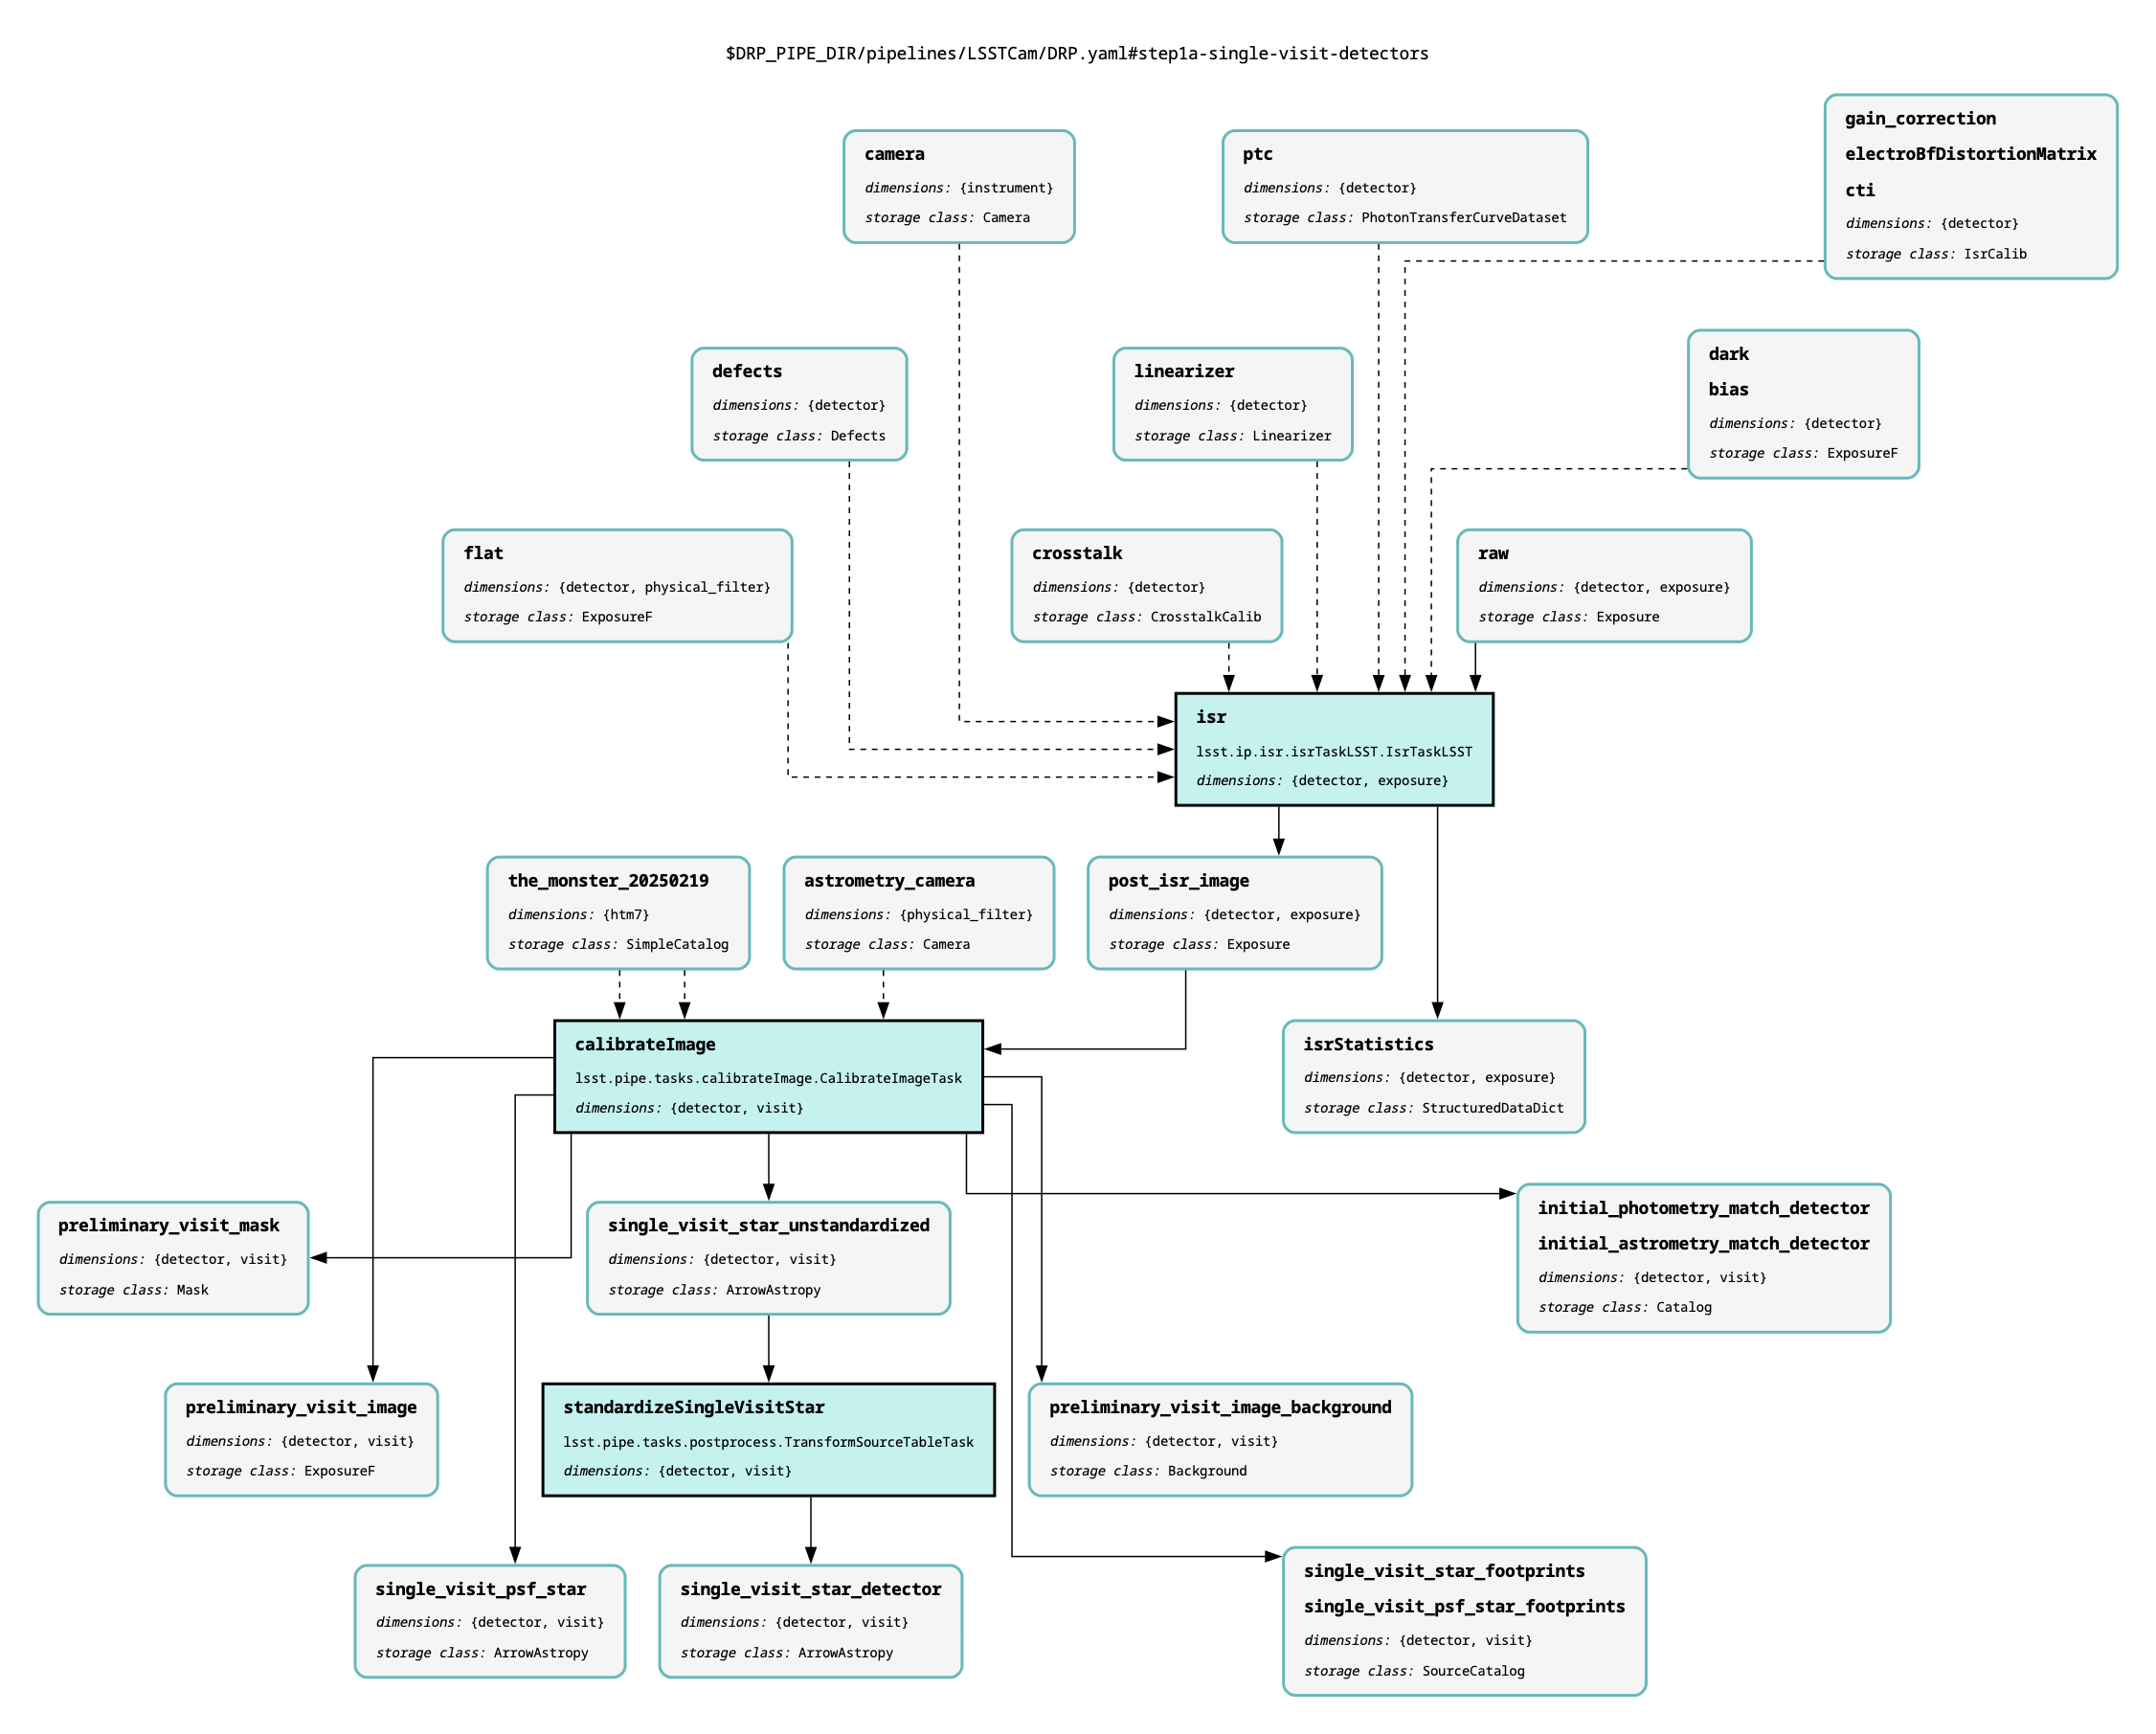

In [4]:
# figure with quantum diagram
filename_diagram = "../fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1a-single-visit-detectors.png"
ShowOneImage(filename_diagram,title="DRP step1a")

/pbs/throng/lsst/users/dagoret/rubin_user/MyRubinLsstRunsatCC/notebooks/fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1b-single-visit-visits.png
True


### DRP step1b

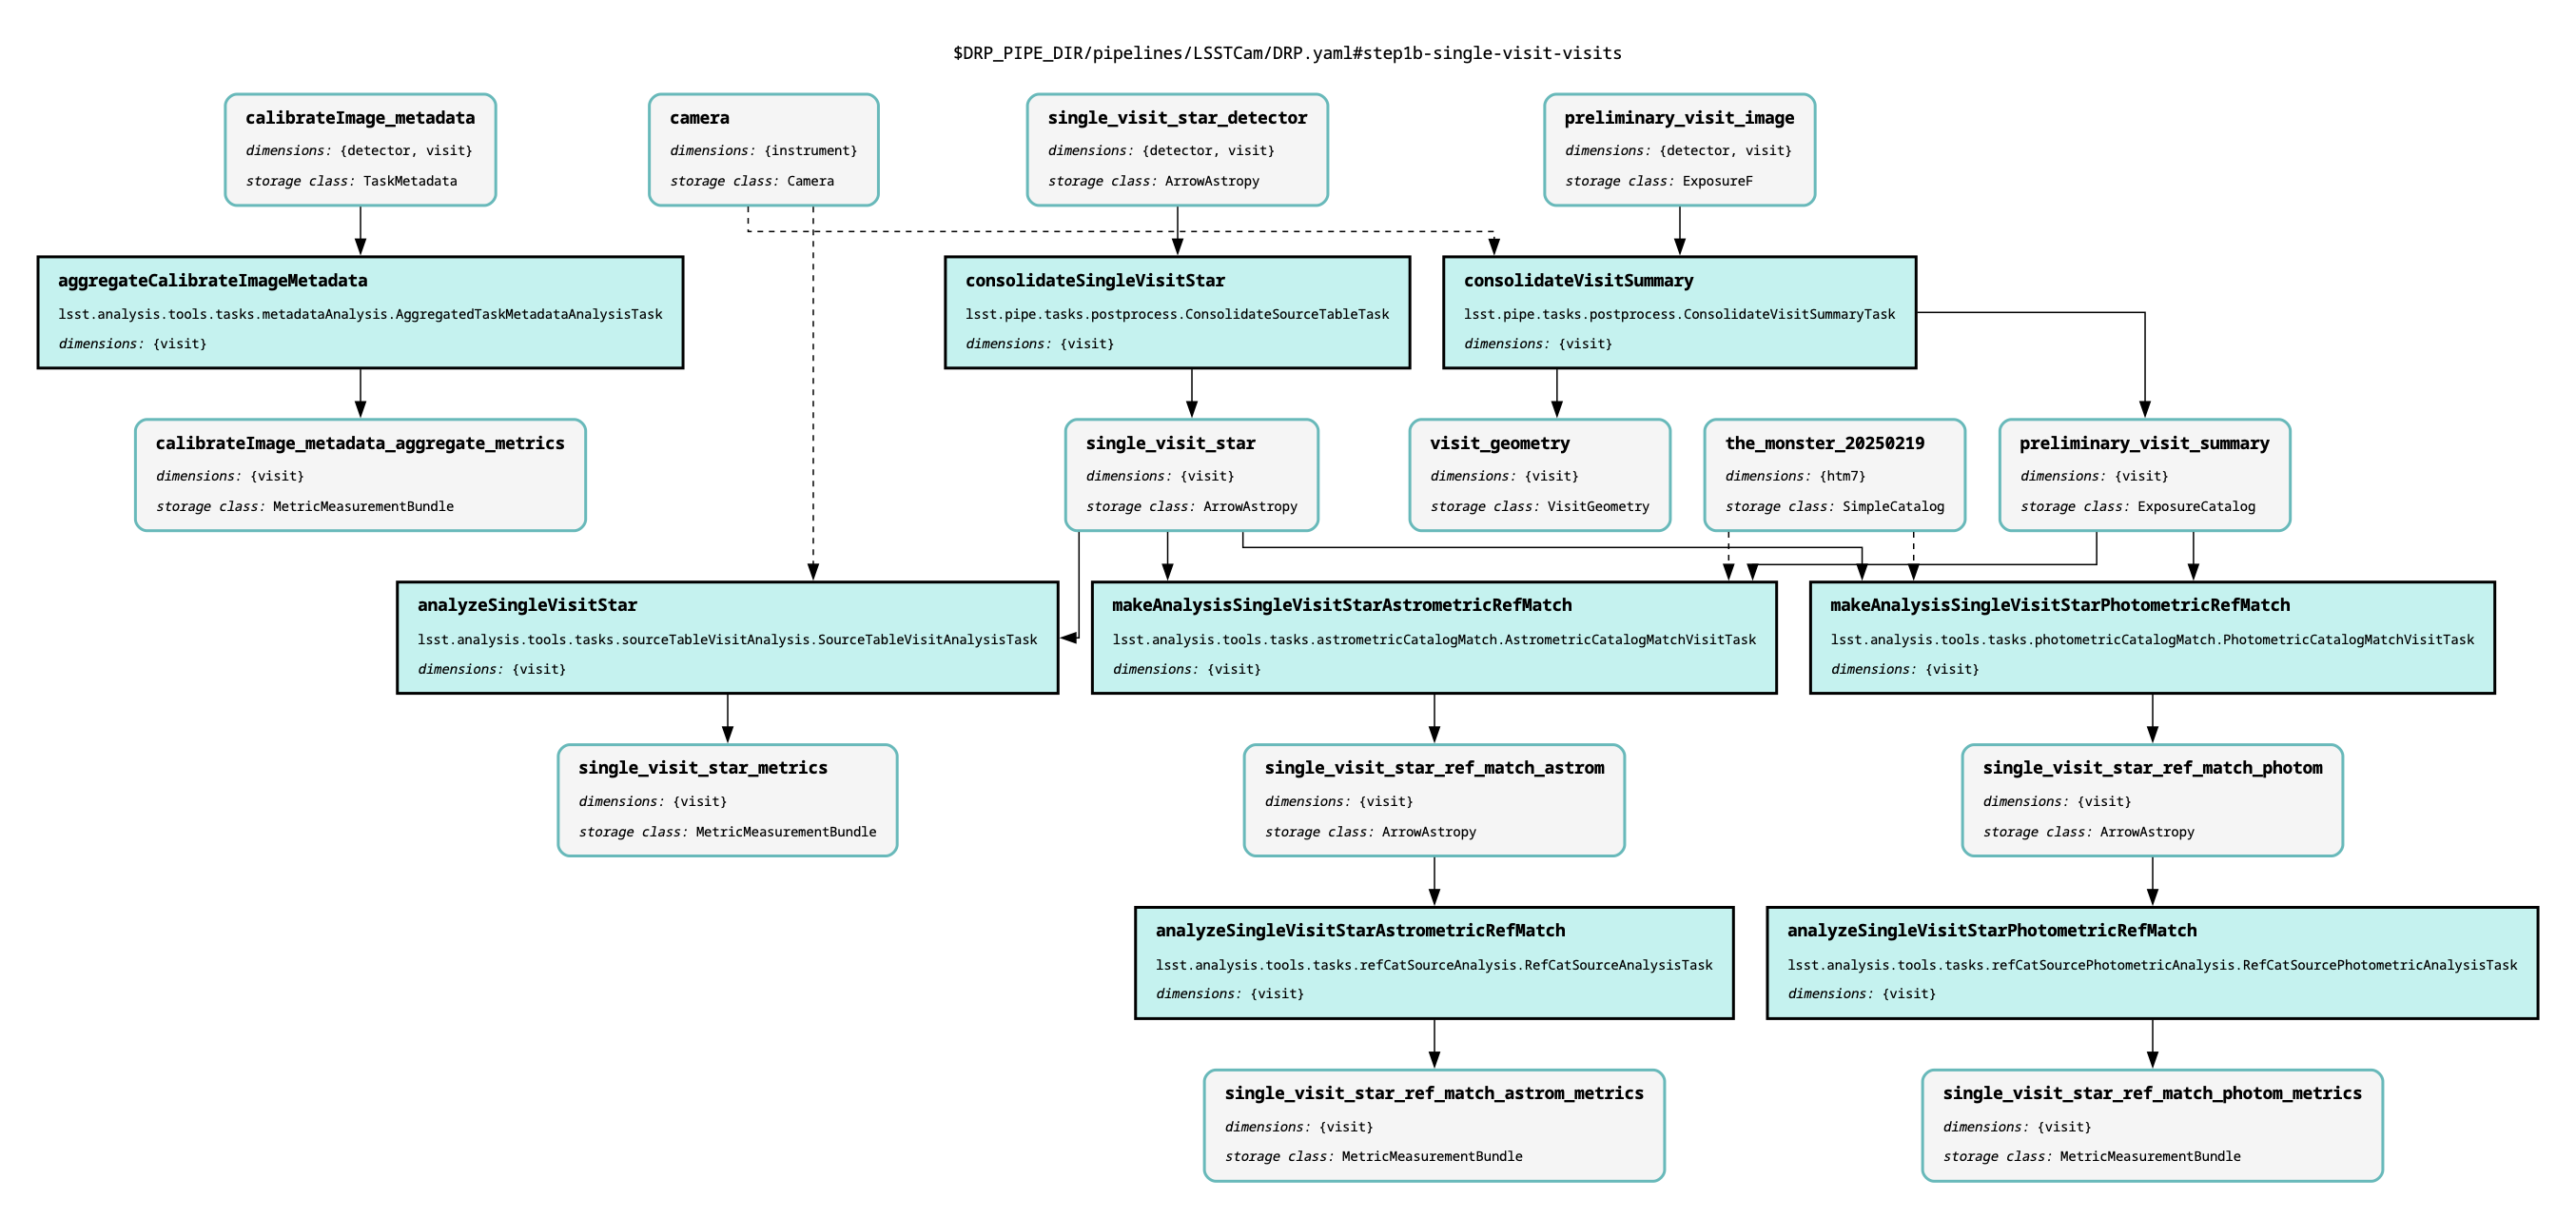

In [5]:
# figure with quantum diagram
filename_diagram = "../fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1b-single-visit-visits.png"
ShowOneImage(filename_diagram,title="DRP step1b")

/pbs/throng/lsst/users/dagoret/rubin_user/MyRubinLsstRunsatCC/notebooks/fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1c-single-visit-tracts.png
True


### DRP step1c

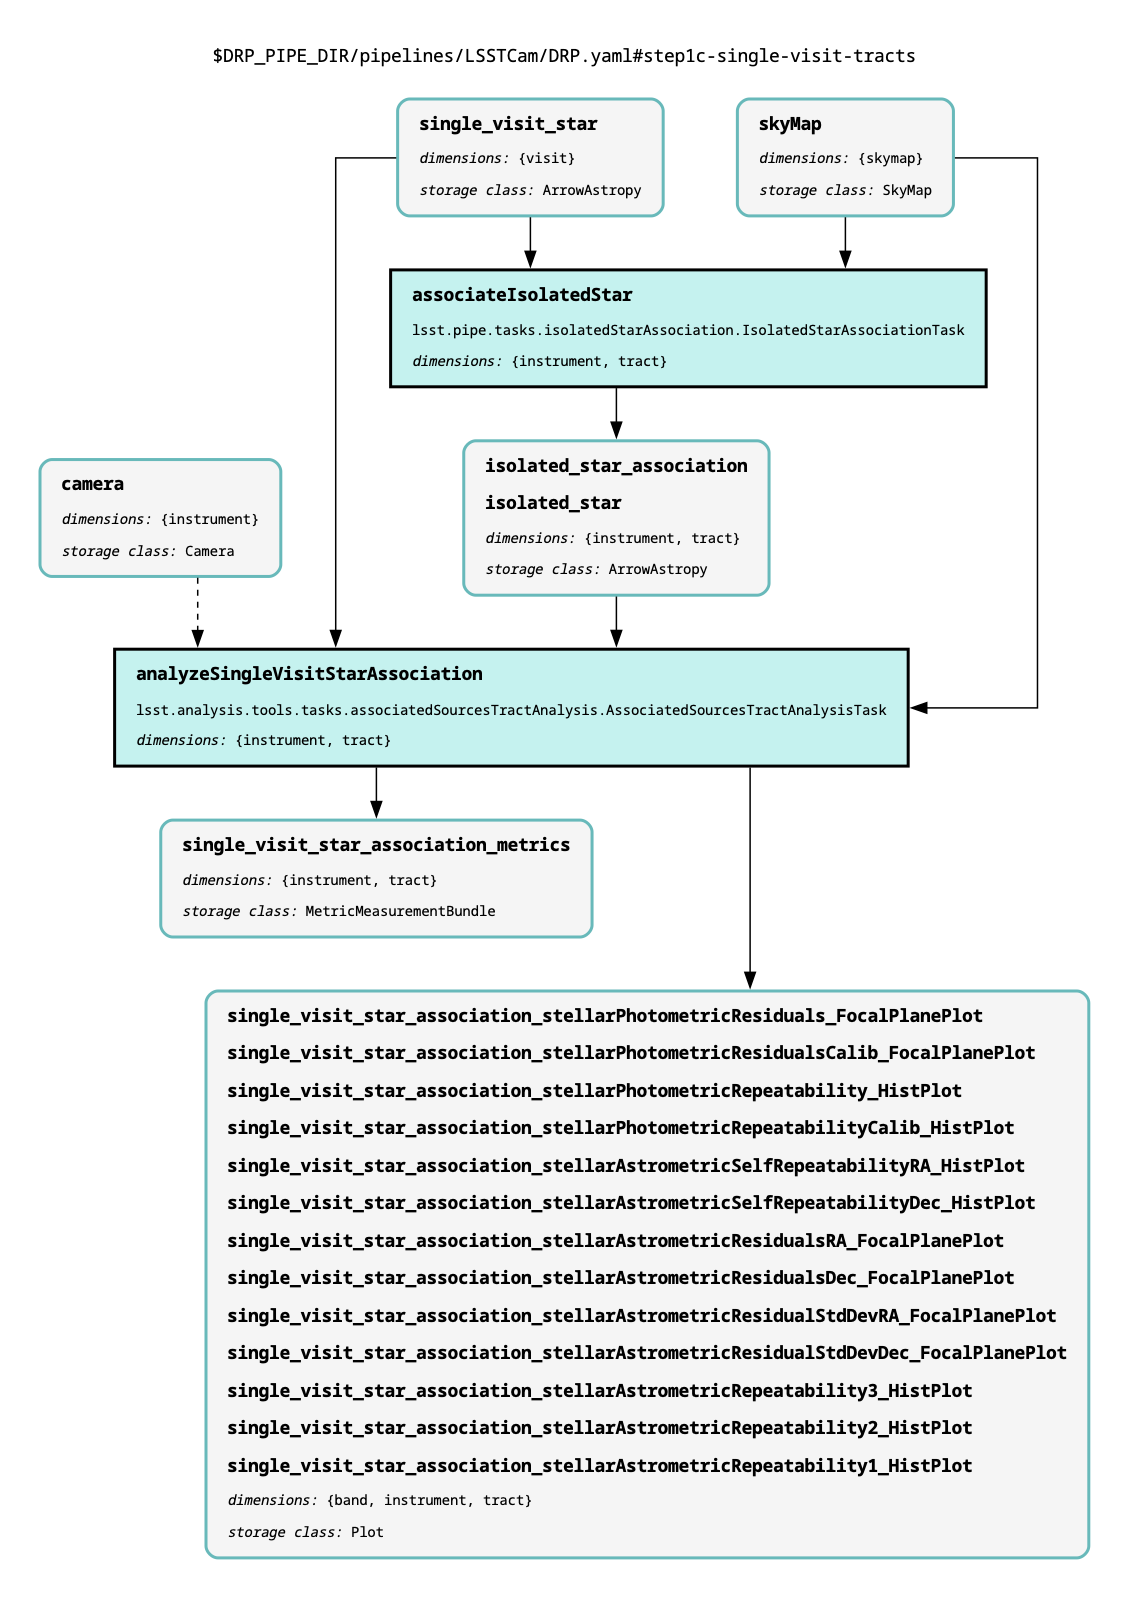

In [6]:
filename_diagram = "../fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1c-single-visit-tracts.png"
ShowOneImage(filename_diagram,title="DRP step1c")

/pbs/throng/lsst/users/dagoret/rubin_user/MyRubinLsstRunsatCC/notebooks/fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1d-single-visit-global.png
True


### DRP step1d

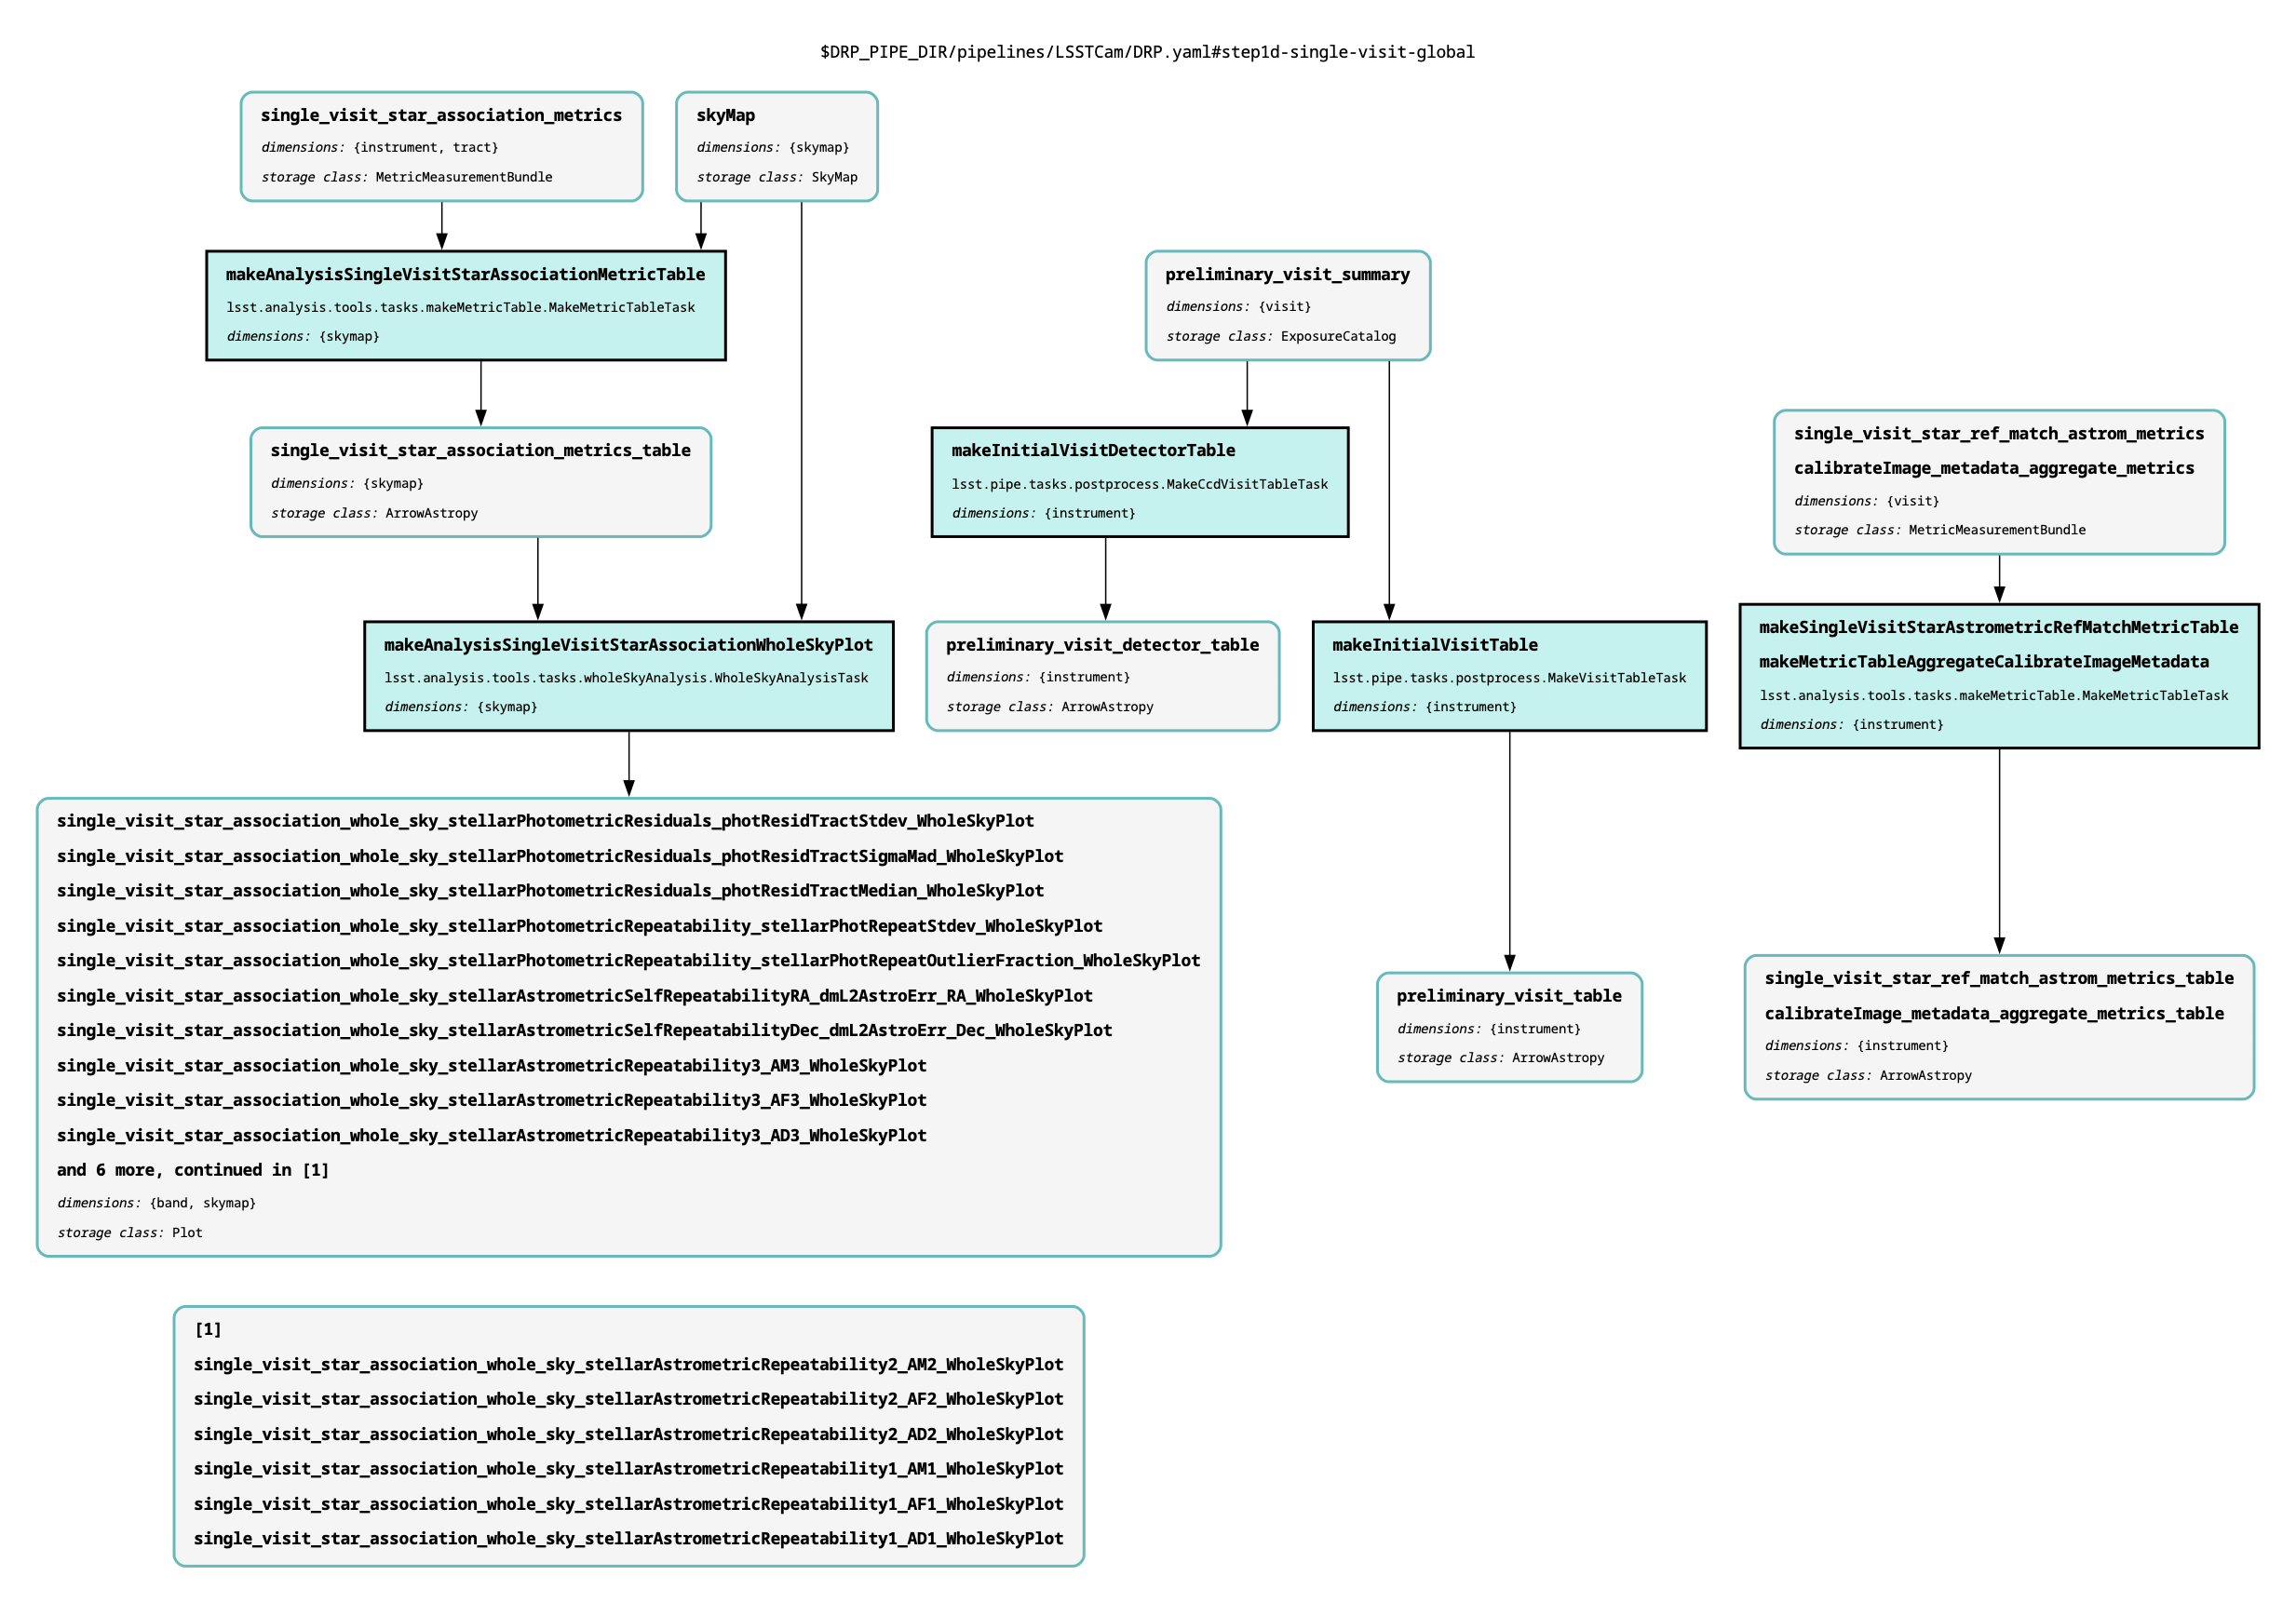

In [7]:
filename_diagram = "../fig_diagrams/pipeline_drp_pipe_LSSTCam_DRP_step1d-single-visit-global.png"
ShowOneImage(filename_diagram,title="DRP step1d")

## 1. Read `preliminary_visit_summary`

In [8]:
run_butler = mon.get_butler(REPO, collections=RUN_COLLECTION)

frames = []
failures = []
for visit in per_visit['visit']:
    try:
        vs = run_butler.get('preliminary_visit_summary', visit=int(visit), instrument='LSSTCam')
        df = mon.as_dataframe(vs)
        df['visit'] = int(visit)
        frames.append(df)
    except Exception as exc:
        failures.append((visit, repr(exc)))
print('failures:', failures[:5])

vs_all = pd.concat(frames, ignore_index=True)
print(vs_all.shape)
print(list(vs_all.columns))

failures: []
(222, 76)
['id', 'bbox_min_x', 'bbox_min_y', 'bbox_max_x', 'bbox_max_y', 'visit', 'physical_filter', 'band', 'psfSigma', 'psfArea', 'psfIxx', 'psfIyy', 'psfIxy', 'raCorners', 'decCorners', 'ra', 'dec', 'zenithDistance', 'pixelScale', 'expTime', 'zeroPoint', 'skyBg', 'skyNoise', 'meanVar', 'psfAdaptiveThresholdValue', 'psfAdaptiveIncludeThresholdMultiplier', 'nShapeletsStar', 'shapeletsOnlyIqScore', 'shapeletsIqScore', 'centroidDiffShapeletsVsSlotMedian', 'shapeletsStarEMedian', 'shapeletsStarUnNormalizedEMedian', 'refCatSourceDensity', 'astromOffsetMean', 'astromOffsetStd', 'nPsfStar', 'psfStarDeltaE1Median', 'psfStarDeltaE2Median', 'psfStarDeltaE1Scatter', 'psfStarDeltaE2Scatter', 'psfStarDeltaSizeMedian', 'psfStarDeltaSizeScatter', 'psfStarScaledDeltaSizeScatter', 'psfTraceRadiusDelta', 'psfApFluxDelta', 'psfApCorrSigmaScaledDelta', 'maxDistToNearestPsf', 'starEMedian', 'starUnNormalizedEMedian', 'starComa1Median', 'starComa2Median', 'starTrefoil1Median', 'starTrefoil2Me

In [9]:
# detector column: the summary is an ExposureCatalog whose id is the detector id
det_col = 'detector_id' if 'detector_id' in vs_all.columns else 'id'
vs_all['detector'] = vs_all[det_col]

# numeric quantities of interest, kept only if present in this pipeline version
WANTED = ['zeroPoint', 'psfSigma', 'psfArea', 'skyBg', 'skyNoise', 'nPsfStar', 'astromOffsetMean',
          'astromOffsetStd', 'zenithDistance', 'effTime', 'magLim', 'expTime']
# PSF-model quality and PSF-versus-aperture flux diagnostics
PSFQ = ['psfApFluxDelta', 'psfApCorrSigmaScaledDelta', 'psfTraceRadiusDelta', 'psfStarDeltaSizeMedian',
        'psfStarScaledDeltaSizeScatter', 'psfStarDeltaE1Median', 'psfStarDeltaE2Median', 'refCatSourceDensity',
        'shapeletsIqScore', 'maxDistToNearestPsf']
ALL_WANTED = WANTED + PSFQ
KEY = [c for c in ALL_WANTED if c in vs_all.columns]
print('available:', KEY)
print('missing  :', [c for c in ALL_WANTED if c not in vs_all.columns])
vs_all[['visit', 'detector'] + KEY].describe().T.round(4)

available: ['zeroPoint', 'psfSigma', 'psfArea', 'skyBg', 'skyNoise', 'nPsfStar', 'astromOffsetMean', 'astromOffsetStd', 'zenithDistance', 'effTime', 'magLim', 'expTime', 'psfApFluxDelta', 'psfApCorrSigmaScaledDelta', 'psfTraceRadiusDelta', 'psfStarDeltaSizeMedian', 'psfStarScaledDeltaSizeScatter', 'psfStarDeltaE1Median', 'psfStarDeltaE2Median', 'refCatSourceDensity', 'shapeletsIqScore', 'maxDistToNearestPsf']
missing  : []


,count,mean,std,min,25%,50%,75%,max
visit,222.0,2.025514e+12,4.845258e+08,2.025052e+12,2.025052e+12,2.025053e+12,2.026022e+12,2.026023e+12
detector,222.0,9.280180e+01,1.637940e+01,5.100000e+01,8.925000e+01,9.300000e+01,9.675000e+01,1.380000e+02
zeroPoint,212.0,3.140820e+01,7.667000e-01,3.033690e+01,3.047030e+01,3.178220e+01,3.215030e+01,3.227610e+01
psfSigma,222.0,2.371100e+00,3.166000e-01,1.828300e+00,2.122300e+00,2.341900e+00,2.548100e+00,3.206300e+00
psfArea,222.0,8.935010e+01,2.341110e+01,5.240390e+01,7.040080e+01,8.582330e+01,1.069452e+02,1.432156e+02
skyBg,222.0,2.580157e+03,2.491337e+03,4.989510e+01,7.819504e+02,1.958651e+03,3.973989e+03,1.079642e+04
skyNoise,222.0,4.525460e+01,2.411690e+01,8.322700e+00,2.854600e+01,4.459800e+01,6.336690e+01,1.050773e+02
nPsfStar,222.0,1.181396e+02,4.573640e+01,3.200000e+01,9.125000e+01,1.190000e+02,1.510000e+02,2.170000e+02
astromOffsetMean,222.0,7.636000e-01,3.732200e+00,6.200000e-03,9.900000e-03,1.170000e-02,1.530000e-02,2.500190e+01
astromOffsetStd,222.0,3.589000e-01,1.754100e+00,3.100000e-03,5.600000e-03,6.600000e-03,8.500000e-03,1.183850e+01


## 2. Clean versus bad visits

In [10]:
# median over detectors of each quantity, per visit, next to the Monster comparison
summ = vs_all.groupby('visit')[KEY].median().reset_index()
tbl = per_visit.merge(summ, on='visit', how='left').sort_values(['band', 'visit']).reset_index(drop=True)
# the zero point is defined for counts, so it depends on the exposure time: normalise it to 30 s
# (check: the 15 s visits should have a zero point about 0.75 mag lower than 30 s visits of the same band)
extra = []
if 'zeroPoint' in KEY and 'expTime' in KEY:
    tbl['zeroPoint_30s'] = tbl['zeroPoint'] - 2.5 * np.log10(tbl['expTime'] / 30.0)
    clean_med = tbl[~tbl['bad']].groupby('band')['zeroPoint_30s'].median()
    tbl['dZP_vs_clean'] = tbl['zeroPoint_30s'] - tbl['band'].map(clean_med)
    extra = ['zeroPoint_30s', 'dZP_vs_clean']
tbl.to_csv(DATA_DIR / f'{NB_TAG}_per_visit_table.csv', index=False)
cols = (['visit', 'band', 'bad'] + [c for c in ('observation_reason',) if c in tbl.columns]
        + ['median_dmag', 'sigma_mad'] + [c for c in KEY if c not in PSFQ] + extra)
print(tbl[cols].round(4).to_string(index=False))
print()
print(tbl[['visit', 'band', 'bad'] + [c for c in PSFQ if c in tbl.columns]].round(4).to_string(index=False))

# does a PSF-quality indicator separate the bad visits? (threshold to be tuned on more visits)
if 'shapeletsIqScore' in tbl.columns:
    print()
    print(pd.crosstab(tbl['bad'], tbl['shapeletsIqScore'] > 0.05,
                      rownames=['bad (sigma_MAD > 0.03)'], colnames=['shapeletsIqScore > 0.05']))

        visit band   bad                  observation_reason  median_dmag  sigma_mad  zeroPoint  psfSigma    psfArea        skyBg   skyNoise  nPsfStar  astromOffsetMean  astromOffsetStd  zenithDistance   effTime    magLim   expTime  zeroPoint_30s  dZP_vs_clean
2025052000110    g False                field_survey_science      -0.0071     0.0142  31.787600    2.4462  90.464302   778.030884  28.503799     100.0            0.0192           0.0111       35.930000  4.556400 23.946899 30.000999      31.787600       -0.4730
2026021800269    g False                        alert_cosmos      -0.0038     0.0130  32.271198    2.4404  95.897003   665.098999  26.247101     117.0            0.0184           0.0108       32.287102 12.352200 24.488300 30.000999      32.271099        0.0106
2026022400618    g False                        alert_cosmos      -0.0041     0.0131  32.260601    2.1312  64.451302  1321.010498  36.509201     122.0            0.0201           0.0110       34.084702  9.240800 24.33

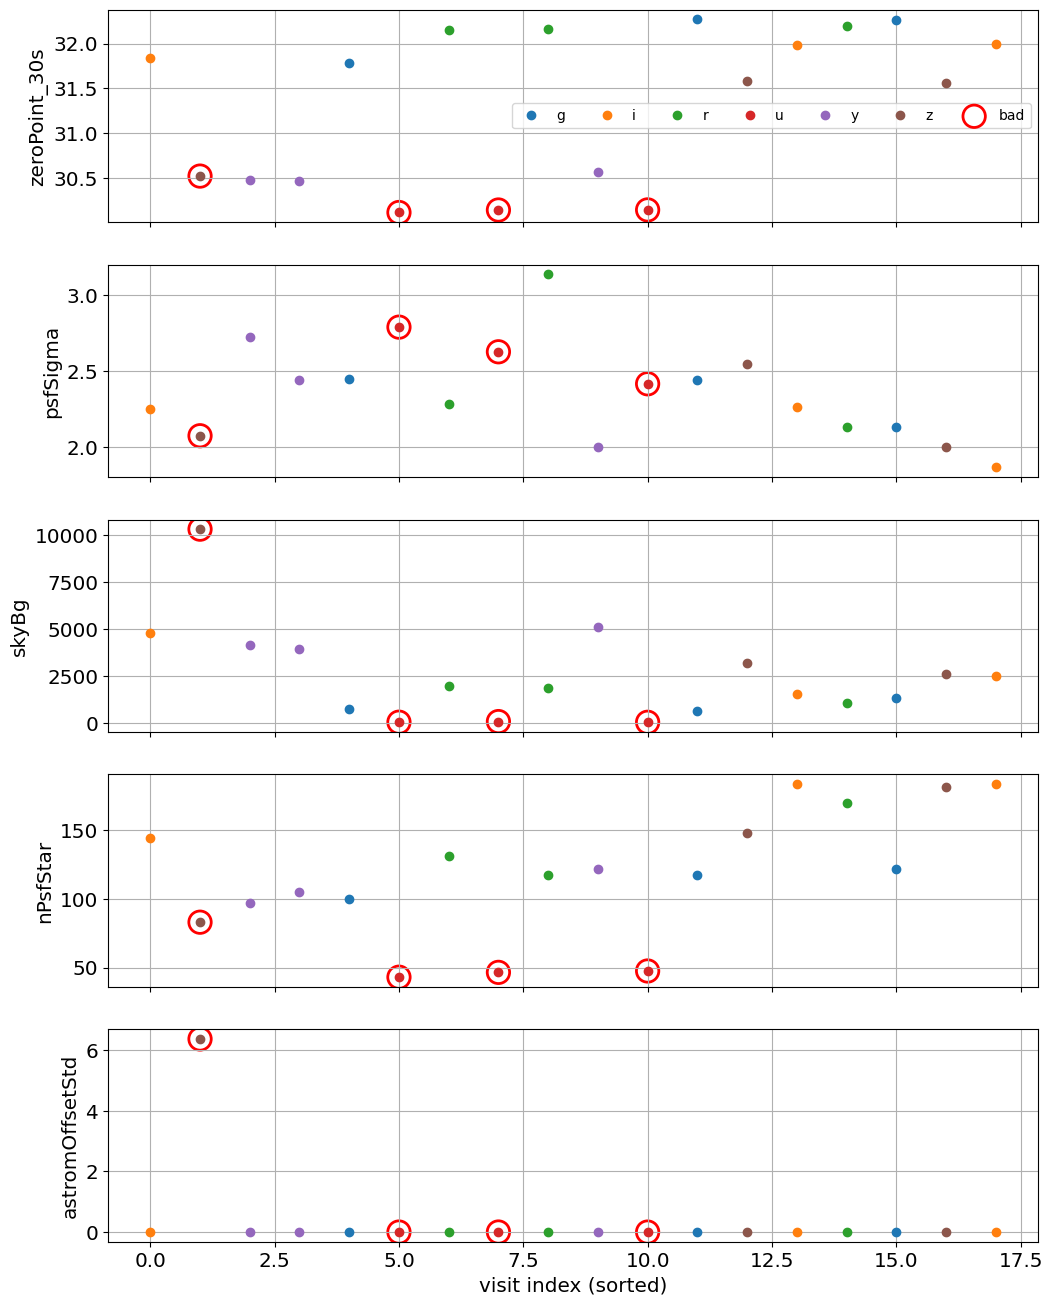

In [11]:
# the same quantities against the visit order, bad visits circled in red
plot_vars = [c for c in ('zeroPoint_30s', 'psfSigma', 'skyBg', 'nPsfStar', 'astromOffsetStd') if c in tbl.columns]
order = {v: i for i, v in enumerate(sorted(tbl['visit']))}
tbl['x'] = tbl['visit'].map(order)
bands = sorted(tbl['band'].unique())

fig, axes = plt.subplots(len(plot_vars), 1, figsize=(12, 3.2 * len(plot_vars)), squeeze=False, sharex=True)
for ax, var in zip(axes.ravel(), plot_vars):
    for band in bands:
        s = tbl[tbl['band'] == band]
        ax.plot(s['x'], s[var], 'o', label=band)
    b = tbl[tbl['bad']]
    ax.scatter(b['x'], b[var], s=260, facecolors='none', edgecolors='r', linewidths=2, label='bad')
    ax.set_ylabel(var)
    ax.grid()
axes.ravel()[0].legend(ncol=len(bands) + 1)
axes.ravel()[-1].set_xlabel('visit index (sorted)')
savefig(fig, 'visit_summary_vs_visit')

## 3. Detector level for the bad visits

Per-detector medians of dmag (notebook 02) next to the per-detector quantities of the summary.

In [12]:
per_det = pd.read_csv(NB02_DIR / 'summary_per_detector.csv')
dtbl = per_det.merge(vs_all[['visit', 'detector'] + KEY], on=['visit', 'detector'], how='left')
dtbl = dtbl.merge(per_visit[['visit', 'bad']], on='visit', how='left')
dtbl.to_csv(DATA_DIR / f'{NB_TAG}_per_detector_table.csv', index=False)

bad_visits = per_visit.loc[per_visit['bad'], 'visit'].tolist()
show = ['visit', 'band', 'detector', 'sensor_type', 'n', 'median_dmag', 'sigma_mad'] + [c for c in KEY if c in ('zeroPoint', 'psfSigma', 'skyBg', 'nPsfStar', 'astromOffsetMean')]
print(dtbl[dtbl['visit'].isin(bad_visits)][show].round(4).to_string(index=False))
print()
psfq_show = ['visit', 'band', 'detector'] + [c for c in PSFQ if c in dtbl.columns]
print(dtbl[dtbl['visit'].isin(bad_visits)][psfq_show].round(4).to_string(index=False))

        visit band  detector sensor_type   n  median_dmag  sigma_mad  zeroPoint  psfSigma        skyBg  nPsfStar  astromOffsetMean
2025051500148    z        90         E2V 118      -0.0043     0.0424  30.518801    2.0756 10121.735352        83            0.0129
2025051500148    z        93         E2V 118      -0.0006     0.0243  30.546000    2.0432 10029.818359        81            0.0107
2025051500148    z        98         E2V 101      -0.0003     0.0585  30.393600    2.0760 10788.368164        81            0.0117
2025052000142    u        51         E2V  22       0.0055     0.0362  30.372400    2.7881    56.979000        43            0.0108
2025052000142    u        52         E2V  20       0.0147     0.0411  30.398899    2.8115    57.249199        49            0.0124
2025052000142    u        86         E2V  18       0.0029     0.0546  30.375099    2.7410    57.083900        44            0.0073
2025052000142    u        89         E2V  19      -0.0192     0.0253  30.349800    

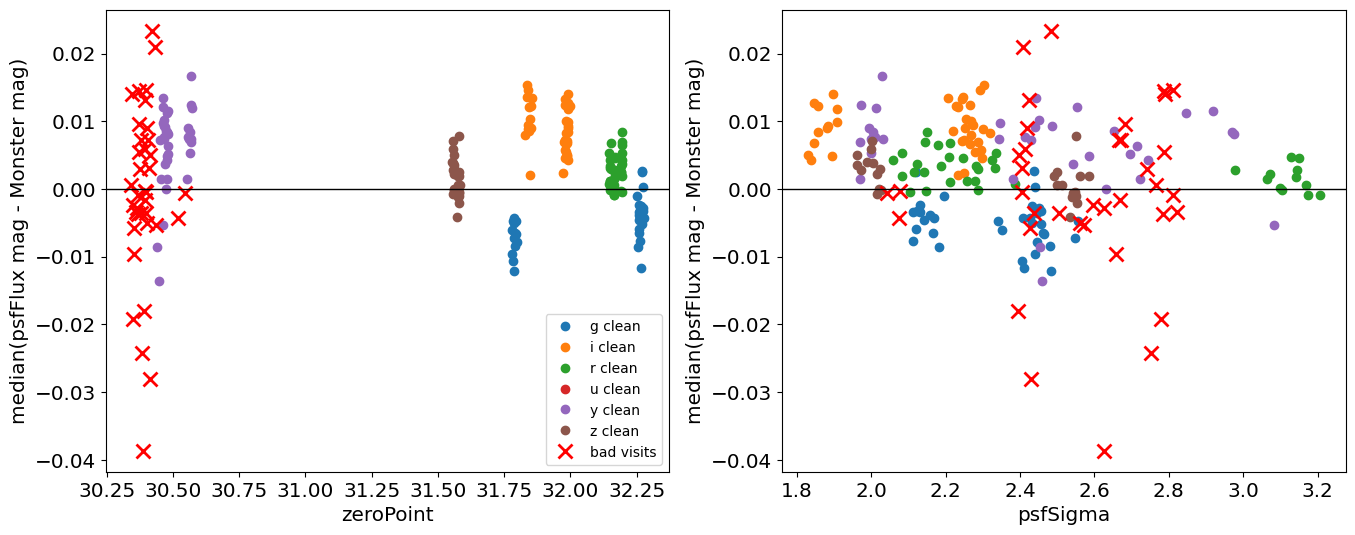

In [13]:
# detector-level view: is the offset of a detector related to the zero point or PSF size of that detector?
xvars = [c for c in ('zeroPoint', 'psfSigma') if c in dtbl.columns]
fig, axes = plt.subplots(1, len(xvars), figsize=(8 * len(xvars), 6), squeeze=False)
for ax, var in zip(axes.ravel(), xvars):
    for band in bands:
        s = dtbl[(dtbl['band'] == band) & (~dtbl['bad'])]
        ax.plot(s[var], s['median_dmag'], 'o', label=f'{band} clean')
    b = dtbl[dtbl['bad']]
    ax.plot(b[var], b['median_dmag'], 'rx', ms=10, mew=2, label='bad visits')
    ax.axhline(0, color='k', lw=1)
    ax.set_xlabel(var)
    ax.set_ylabel('median(psfFlux mag - Monster mag)')
axes.ravel()[0].legend()
savefig(fig, 'dmag_vs_summary_quantities')